# Concept Convergence: Context Displacement Trajectories

Give this notebook a list of "concept lists" (groups of related words) and it plots
how their context-displacement vectors move through a shared 2D PCA space as more context
tokens are added -- visualizing whether same-concept words "converge" toward a shared direction.

**Workflow**
1. Run the setup cells once (loads the model, and fits a 2D PCA basis from `categories_data.csv`
   so trajectories from different calls land in the same, comparable space).
2. Call `plot_convergence(...)` with any list of concept lists to get a graph

Each concept list's trajectory is residualized against a position-only baseline (`mean_disp`),
estimated once per context length from random background token samples

In [2]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from tqdm.notebook import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer


REPO_PATH = "./"
print(os.getcwd())
SRC_DIR = os.path.join(REPO_PATH, "src")
sys.path.insert(0, SRC_DIR)
from helpers import data as data_module

/oscar/data/epavlick/mlepori/projects/rerepresentation/few_shot


In [3]:
MODEL_NAME = "google/gemma-2-2b"
DATA_PATH  = os.path.join(REPO_PATH, "data", "categories_data.csv")
SEED       = 42

DISPLAY_LAYER           = 16   # hidden_states index the PCA basis (and plots) are computed at
N_TRAIN_SUPPORTS        = 20   # background support sets per category, for the PCA basis
BACKGROUND_SUPPORT_LEN  = 4    # Number of items in the background support sets
N_MEAN_DISP_SAMPLES     = 200  # random samples used to estimate the position-only context effect per context length

rng = np.random.default_rng(SEED)

In [4]:
print(f"Loading model: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype="auto", trust_remote_code=True)
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
context_id = tokenizer.bos_token_id

print(f"Context ID: {context_id}")
print(f"Model on {device}")

Loading model: google/gemma-2-2b


Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Context ID: 2
Model on cuda


## Background PCA basis

Fits a 2D PCA basis from `categories_data.csv`'s per-category mean displacement vectors, so
any concept list's trajectory (below) can be projected into the same, comparable space. This needs to run once per `DISPLAY_LAYER`.

In [5]:
def get_states(input_str):
    """Return (n_layers, d) hidden states for the last token of input_str."""
    token_ids = tokenizer.encode(input_str, add_special_tokens=False)
    input_ids = torch.tensor([[context_id] + token_ids], device=device)
    with torch.no_grad():
        outputs = model(input_ids, output_hidden_states=True)
    return torch.stack([h[0, -1, :].cpu().float() for h in outputs.hidden_states])


isolated_states = {}  # word -> (n_layers, d), cached lazily as new words are seen


def get_isolated_state(word):
    if word not in isolated_states:
        isolated_states[word] = get_states(" " + word.strip())
    return isolated_states[word]

In [6]:
raw_data = pd.read_csv(DATA_PATH)
filtered_data = data_module.filter_multitoken_data(raw_data, tokenizer)
all_cats = sorted(filtered_data["category"].unique().tolist())
all_cat_members = {
    cat: filtered_data[filtered_data["category"] == cat]["category.member"].tolist()
    for cat in all_cats
}
print(f"{len(all_cats)} background categories, "
      f"{sum(len(m) for m in all_cat_members.values())} members")

print("Caching isolated states for background tokens...")
for tok in tqdm(sorted({t for members in all_cat_members.values() for t in members})):
    get_isolated_state(tok)

113 background categories, 3242 members
Caching isolated states for background tokens...


  0%|          | 0/2378 [00:00<?, ?it/s]

In [7]:
mean_disp_by_len = {}  # context length -> (n_layers, d), cached lazily


def get_mean_disp(context_length):
    """Position-only baseline: mean hidden-state displacement for a random `context_length`-token
    context, averaged over N_MEAN_DISP_SAMPLES random samples from the background token pool.
    """
    if context_length not in mean_disp_by_len:
        pool = list(isolated_states.keys())
        disps = []
        for _ in range(N_MEAN_DISP_SAMPLES):
            sample = rng.choice(pool, size=context_length, replace=False).tolist()
            hs_ctx = get_states(" " + " ".join(sample))
            hs_iso = get_isolated_state(sample[-1])
            disps.append(hs_ctx - hs_iso)
        mean_disp_by_len[context_length] = torch.stack(disps).mean(dim=0)  # (n_layers, d)
    return mean_disp_by_len[context_length]


# Pre-compute for the background support length now, so the PCA-basis cell below doesn't stall.
get_mean_disp(BACKGROUND_SUPPORT_LEN)
print("done")

done


In [8]:
print("Computing per-category mean displacement vectors...")
cat_mean_disps = {}
for cat in tqdm(all_cats):
    members = all_cat_members[cat]
    if len(members) < BACKGROUND_SUPPORT_LEN:
        continue
    disps = []
    for _ in range(N_TRAIN_SUPPORTS):
        support = rng.choice(members, size=BACKGROUND_SUPPORT_LEN, replace=False).tolist()
        hs_ctx = get_states(" " + " ".join(support))
        hs_iso = get_isolated_state(support[-1])
        disp = (hs_ctx[DISPLAY_LAYER] - hs_iso[DISPLAY_LAYER]
                - get_mean_disp(BACKGROUND_SUPPORT_LEN)[DISPLAY_LAYER])
        disps.append(disp)
    cat_mean_disps[cat] = torch.stack(disps).mean(dim=0)

cat_names = sorted(cat_mean_disps.keys())
mean_disp_matrix = np.stack([cat_mean_disps[c].numpy() for c in cat_names])  # (n_cats, d)

print("PCA the per-category mean displacement vectors")
pca = PCA(n_components=2)
pca.fit(mean_disp_matrix)
print(f"PCA explained variance (2 components): {pca.explained_variance_ratio_.round(3)}")

Computing per-category mean displacement vectors...


  0%|          | 0/113 [00:00<?, ?it/s]

PCA the per-category mean displacement vectors
PCA explained variance (2 components): [0.243 0.116]


## Plot convergence

`plot_convergence` is the whole visualization loop: give it a list of concept lists (each a
list of words, or a single space-separated string) and it plots each one's context-displacement
trajectory in the PCA space above, from 2 tokens of context up to the full list.

In [39]:
def compute_trajectory(concept_tokens, display_layer=DISPLAY_LAYER):
    """Residualized context-displacement vector at every context length from 2 tokens up to
    len(concept_tokens), at display_layer.

    Returns:
        trajectory: (n_ctx, d) array
        context_lengths: matching list of context lengths
    """
    if isinstance(concept_tokens, str):
        concept_tokens = concept_tokens.strip().split()
    assert len(concept_tokens) >= 2, "concept lists need at least 2 words to show a trajectory"

    context_lengths = list(range(2, len(concept_tokens) + 1))
    trajectory = []
    for cl in context_lengths:
        context_toks = concept_tokens[:cl]
        hs_ctx = get_states(" " + " ".join(context_toks))
        hs_iso = get_isolated_state(context_toks[-1])
        disp = hs_ctx[display_layer] - hs_iso[display_layer] - get_mean_disp(cl)[display_layer]
        trajectory.append(disp.numpy())
    return np.stack(trajectory), context_lengths


def resolve_ground_truth(gt, display_layer=DISPLAY_LAYER):
    """Turn a single ground_truth entry into a raw (d,) displacement vector at display_layer.

    gt: a category name (str) present in `cat_mean_disps` (the background categories the
          PCA basis was fit from) -- its mean training-set displacement
    """
    if display_layer != DISPLAY_LAYER:
        raise ValueError(
            "Category-name ground_truth lookups use cat_mean_disps, which was only "
            f"computed at DISPLAY_LAYER={DISPLAY_LAYER}; rerun the PCA-basis cell at the new layer."
        )
    return cat_mean_disps[gt].numpy()


def plot_convergence(concept_lists, labels=None, ground_truth=None, ground_truth_labels=None,
                      display_layer=DISPLAY_LAYER, model_name=None, figsize=(5, 4), cmap_name="Dark2",
                      xlim=None, ylim=None, save_path=None):
    """Plot each concept list's context-displacement vectors chained head-to-tail in PCA
    space. Each context length's own (already residualized) displacement vector is
    PCA-projected, then the projected vectors are laid end-to-end (cumulative sum) starting
    from the origin: arrow k starts at the tip of arrow k-1 and points in the direction of
    the ctx=k displacement vector, fading in as context grows.

    Args:
        concept_lists: list of concept lists, each a list of words, 
        e.g. [["robin", "sparrow", "finch", "wren"]]
        labels: optional list of legend labels, one per concept list (defaults to the
            concept list's own text)
        ground_truth: optional list of ground-truth directions, drawn as bold black arrows
            from the origin. Deliberately INDEPENDENT of concept_lists -- pass as many or as
            few as you want (one shared ground truth for several trajectories, several ground
            truths alongside one trajectory, etc). Each entry is a category name.
        ground_truth_labels: optional list of text labels, same length as ground_truth
            (defaults to the category name for str entries, else "ground truth <i>")
        display_layer: hidden_states index to compute displacements at (must match the layer
            the PCA basis above was fit at)
        save_path: if given, also saves the figure there
    """
    if labels is None:
        labels = [cl if isinstance(cl, str) else " ".join(cl) for cl in concept_lists]
    if ground_truth is None:
        ground_truth = []
    assert not isinstance(ground_truth, str), (
        "ground_truth must be a list (e.g. ['bird']), not a bare string."
    )
    if ground_truth_labels is None:
        ground_truth_labels = [
            gt if isinstance(gt, str) else f"ground truth {i}" for i, gt in enumerate(ground_truth)
        ]

    cmap = plt.get_cmap(cmap_name)
    colors = [cmap(i % cmap.N) for i in range(len(concept_lists))]

    # Chain each concept list's per-context-length projected displacement vectors head-to-tail.
    all_waypoints = []  # one (n_ctx+1, 2) array per concept list, starting at the origin
    for concept_tokens in concept_lists:
        trajectory, _ = compute_trajectory(concept_tokens, display_layer)
        proj = pca.transform(trajectory)  # (n_ctx, 2)
        all_waypoints.append(np.vstack([np.zeros((1, 2)), np.cumsum(proj, axis=0)]))

    # Ground-truth arrow length is derived from the trajectories' own scale, so include the
    # trajectory waypoints here.
    data_scale = float(np.abs(np.concatenate(all_waypoints)).max()) * 1.25
    arrow_len = data_scale * 0.8

    fig, ax = plt.subplots(figsize=figsize)

    # ── Trajectories ─────────────────────────────────────────────────────────
    for waypoints, label, color in zip(all_waypoints, labels, colors):
        n_ctx = len(waypoints) - 1
        ctx_alphas = np.linspace(0.4, 1.0, n_ctx)
        for k in range(n_ctx):
            ax.annotate(
                "", xy=waypoints[k + 1], xytext=waypoints[k],
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6,
                                 mutation_scale=12, alpha=ctx_alphas[k]),
            )
        # Proxy line for the legend (arrows have no direct legend entry)
        ax.plot([], [], color=color, linewidth=2, label=label)

    # ── Ground truths ──────
    for gt, gt_label in zip(ground_truth, ground_truth_labels):
        target_proj = pca.transform(resolve_ground_truth(gt, display_layer)[None, :])[0]
        target_norm = np.linalg.norm(target_proj)
        target_dir = target_proj / target_norm 
        tip = target_dir * arrow_len
        ax.annotate(
            "", xy=tip, xytext=(0.0, 0.0),
            arrowprops=dict(arrowstyle="-|>", color="black", lw=2.5, mutation_scale=14),
        )
        ax.text(tip[0] * 1.12, tip[1] * 1.12, gt_label, color="black",
                fontsize=11, fontweight="bold", ha="center", va="center")


    print(data_scale)
    if xlim is None:
        ax.set_xlim(-data_scale, data_scale)
    else:
        ax.set_xlim(xlim[0], xlim[1])
    if ylim is None:
        ax.set_ylim(-data_scale, data_scale)
    else:
        ax.set_ylim(ylim[0], ylim[1])
    ax.set_xticks([])
    ax.set_yticks([])
    if model_name is None:
        model_name = MODEL_NAME
    ax.set_title(f"{model_name}  Layer {display_layer} Context Displacement Vectors",
                 fontsize=13, pad=8)
    if labels:
        ax.legend(fontsize=9, loc="best", framealpha=0.7, title="Concept lists")

    plt.tight_layout()
    plt.show()

    if save_path:
        fig.savefig(save_path, format="pdf", bbox_inches="tight")

    return fig

176.8505096435547


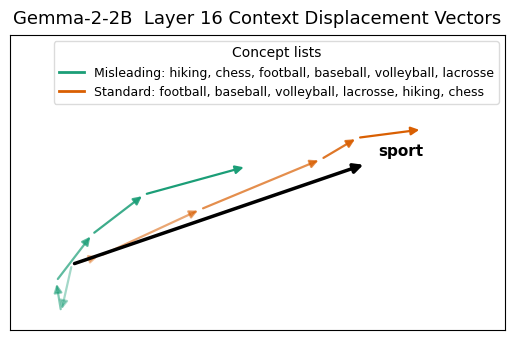

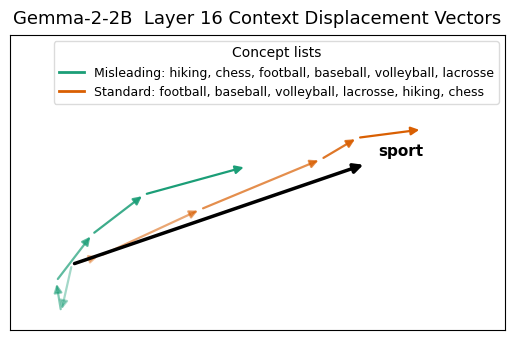

In [53]:
# Main Figure

save_path = "./analysis/Figures_Final/Gemma-2-2B/CDV_sports.pdf"
plot_convergence(
    [
        ["hiking", "chess", "football", "baseball", "volleyball", "lacrosse",],
        ["football", "baseball", "volleyball", "lacrosse", "hiking", "chess",],
    ],
    labels=[
        "Misleading: hiking, chess, football, baseball, volleyball, lacrosse", 
        "Standard: football, baseball, volleyball, lacrosse, hiking, chess"],
    model_name="Gemma-2-2B",
    ground_truth=["sport"],
    save_path=save_path,
    figsize=(5.5, 3.5),
    ylim=(-50, 175),
    xlim=(-25, 175)
)

221.9660186767578


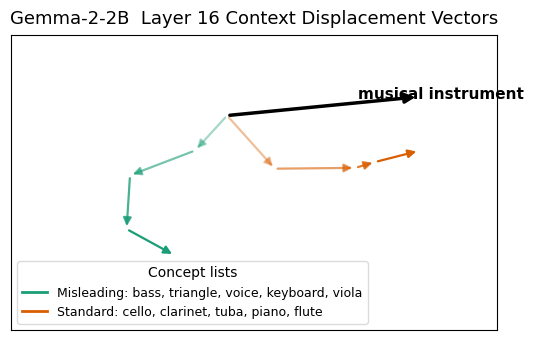

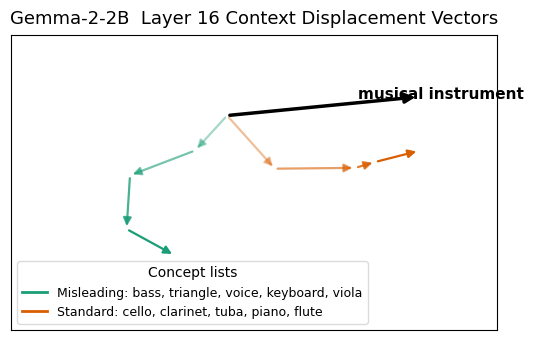

In [ ]:
# Appendix

save_path = "./analysis/Figures_Final/Gemma-2-2B/CDV_instruments.pdf"
plot_convergence(
    [
        ["bass", "triangle", "voice", "keyboard", "viola"],
        ["cello", "clarinet", "tuba", "piano", "flute"],
    ],
    labels=[
        "Misleading: bass, triangle, voice, keyboard, viola", 
        "Standard: cello, clarinet, tuba, piano, flute"],
    model_name="Gemma-2-2B",
    ground_truth=["musical instrument"],
    save_path=save_path,
    figsize=(5.5, 3.5),
    ylim=(-200, 75),
    xlim=(-200, 250)

)

68.12517642974854


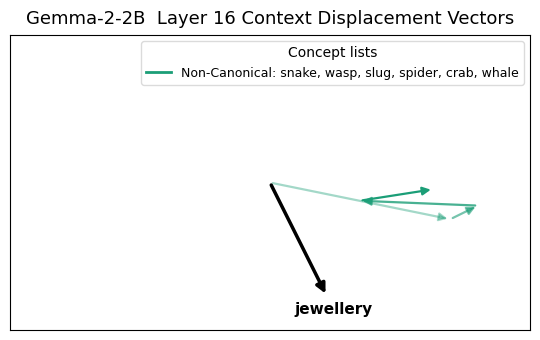

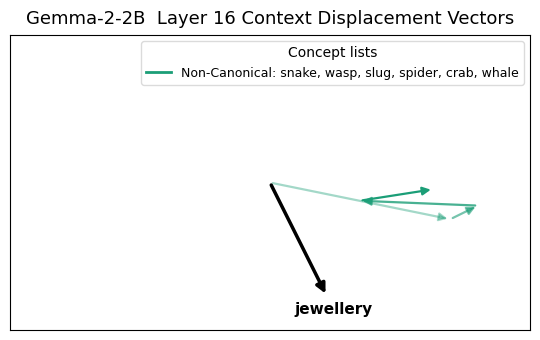

In [ ]:
save_path = "./analysis/Figures_Final/Gemma-2-2B/CDV_fruit.pdf"
plot_convergence(
    [
        ["bracelets", "necklaces", "glasses",  "cap", "jacket",],
        #["monkey", "dog", "cow", "fish", "cat", "frog",],
    ],
    labels=[
        "Non-Canonical: snake, wasp, slug, spider, crab, whale", 
        "Canonical: monkey, dog, cow, fish, cat, frog"],
    model_name="Gemma-2-2B",
    ground_truth=["fruit"],
    save_path=save_path,
    figsize=(5.5, 3.5),
    # ylim=(-200, 75),
    # xlim=(-200, 250)

)

## Example

Growing dot size = increasing context length; the star marks the full concept list.

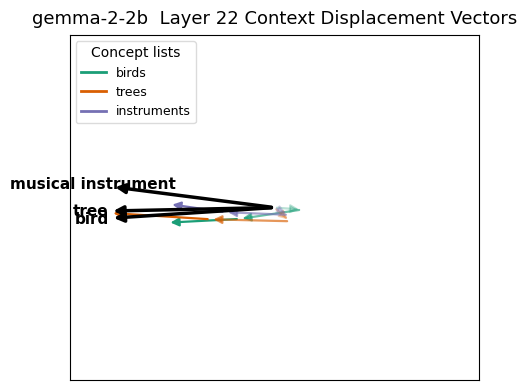

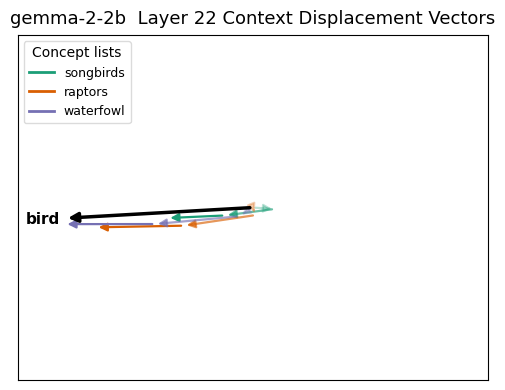

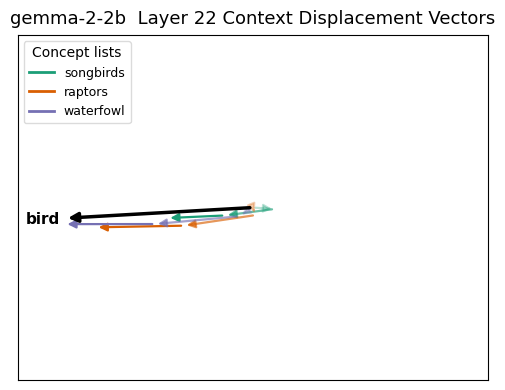

In [29]:
# 3 different trajectories, each with its own ground truth (paired 1:1 by passing 3 of each)
plot_convergence(
    [
        ["robin", "sparrow", "finch", "wren"],
        ["oak", "pine", "maple", "birch"],
        "guitar violin cello trumpet",
    ],
    labels=["birds", "trees", "instruments"],
    # category names here must match categories_data.csv exactly (singular)
    ground_truth=["bird", "tree", "musical instrument"],
)

# Multiple trajectories sharing ONE ground truth -- ground_truth is independent of
# concept_lists, so this just means "pass a single-entry list"
plot_convergence(
    [
        ["robin", "sparrow", "finch", "wren"],
        ["eagle", "hawk", "falcon", "owl"],
        ["duck", "goose", "swan", "heron"],
    ],
    labels=["songbirds", "raptors", "waterfowl"],
    ground_truth=["bird"],
)

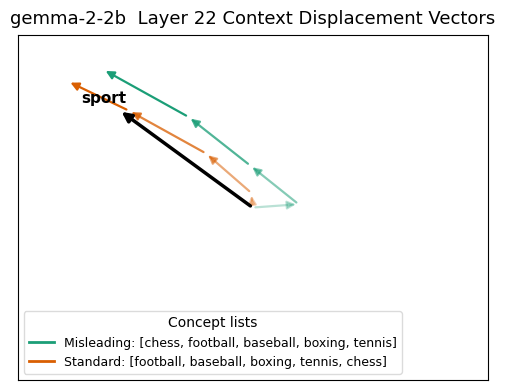

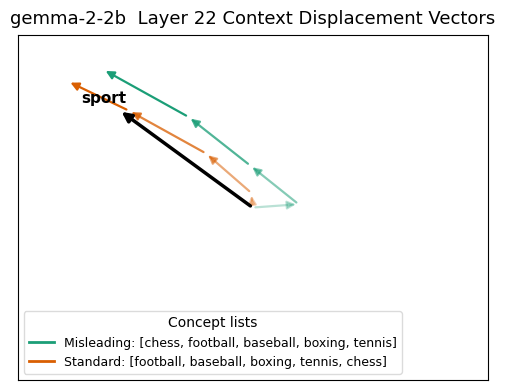

In [44]:
plot_convergence(
    [
        ["chess", "football", "baseball", "boxing", "tennis"],
        ["football", "baseball", "boxing", "tennis", "chess"],
    ],
    labels=[
        "Misleading: [chess, football, baseball, boxing, tennis]", 
        "Standard: [football, baseball, boxing, tennis, chess]"],
    ground_truth=["sport"],
)

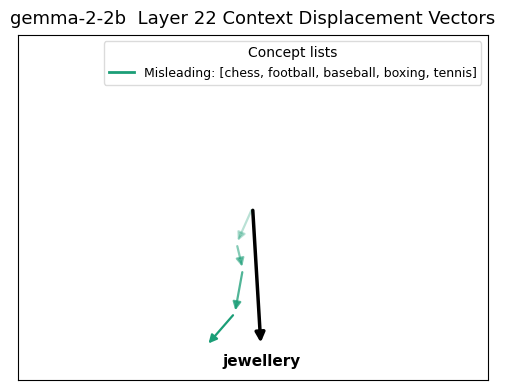

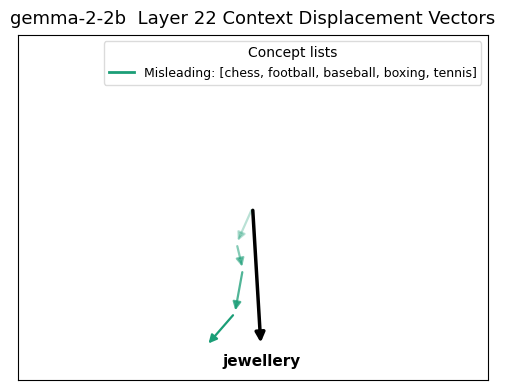

In [41]:
plot_convergence(
    [
        ["bracelets", "necklaces", "glasses",  "cap", "jacket",],
    ],
    labels=[
        "Misleading: [chess, football, baseball, boxing, tennis]", 
        "Standard: [football, baseball, boxing, tennis, chess]"],
    ground_truth=["jewellery"],
)